In [12]:
# CUAD Exploratory Data Analysis
import json
import pandas as pd
import matplotlib.pyplot as plt
with open("../data/cuad/CUADv1.json", "r", encoding="utf-8") as f:
    data = json.load(f)

In [13]:
print("Dataset keys:", data.keys())
print("Number of contracts:", len(data["data"]))
print("Fields in each contract:", data["data"][0].keys())

Dataset keys: dict_keys(['version', 'data'])
Number of contracts: 510
Fields in each contract: dict_keys(['title', 'paragraphs'])


In [14]:
first_contract = data["data"][0]

print("Title:", first_contract["title"])
print("Number of paragraphs:", len(first_contract["paragraphs"]))
print("Paragraph fields:", first_contract["paragraphs"][0].keys())

Title: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
Number of paragraphs: 1
Paragraph fields: dict_keys(['qas', 'context'])


In [15]:
qas = first_contract["paragraphs"][0]["qas"]

print("Number of QAs:", len(qas))
print("QA fields:", qas[0].keys())

Number of QAs: 41
QA fields: dict_keys(['answers', 'id', 'question', 'is_impossible'])


In [16]:
qas[0]

{'answers': [{'text': 'DISTRIBUTOR AGREEMENT', 'answer_start': 44}],
 'id': 'LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Document Name',
 'question': 'Highlight the parts (if any) of this contract related to "Document Name" that should be reviewed by a lawyer. Details: The name of the contract',
 'is_impossible': False}

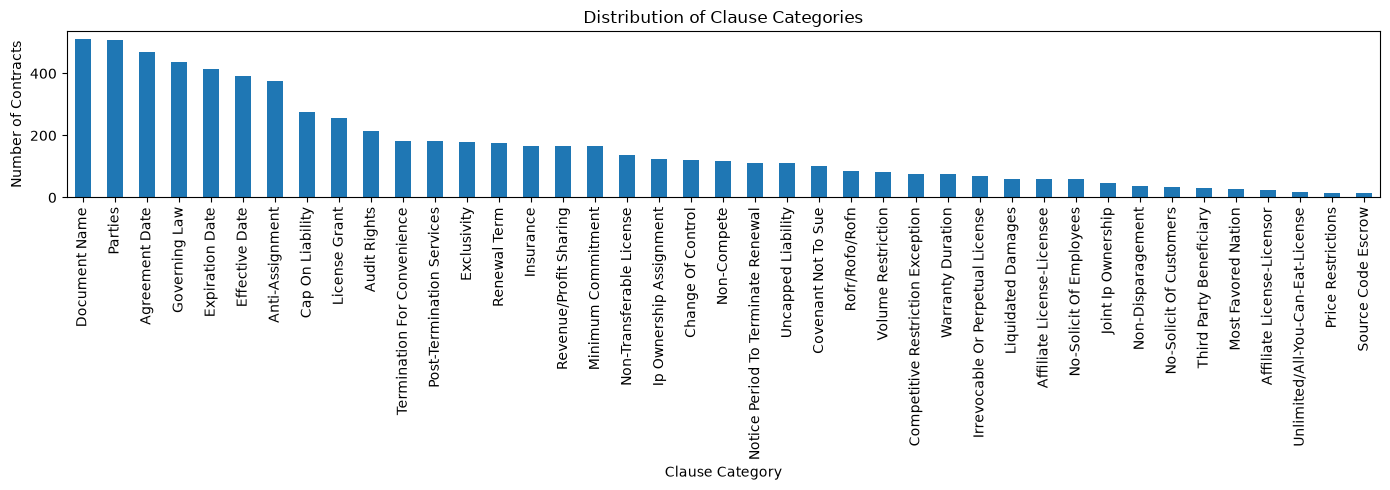

In [17]:
from collections import Counter

clause_counts = Counter()

for contract in data["data"]:
    for paragraph in contract["paragraphs"]:
        for qa in paragraph["qas"]:
            if not qa["is_impossible"]:
                clause = qa["question"].split('"')[1]
                clause_counts[clause] += 1

clause_df = pd.DataFrame(
    clause_counts.items(),
    columns=["Clause Category", "Count"]
).sort_values("Count", ascending=False)

clause_df.plot(
    x="Clause Category",
    y="Count",
    kind="bar",
    figsize=(14, 5),
    legend=False
)

plt.title("Distribution of Clause Categories")
plt.ylabel("Number of Contracts")
plt.tight_layout()
plt.show()

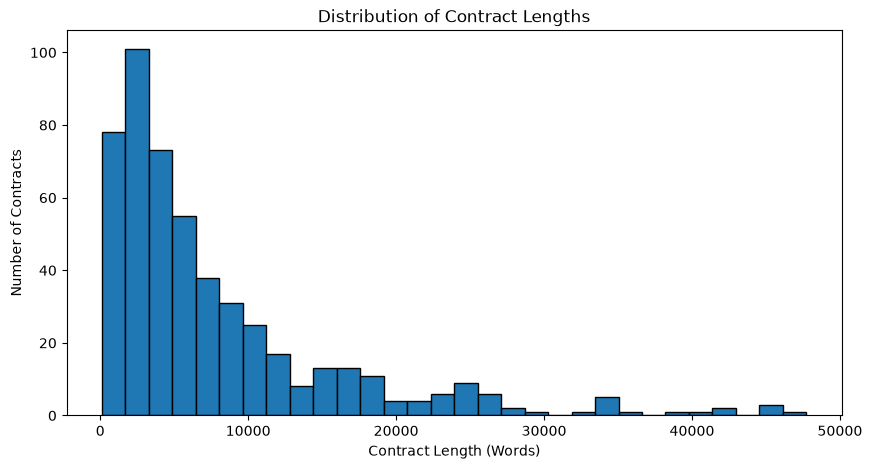

In [18]:
contract_lengths = []

for contract in data["data"]:
    text = " ".join(
        paragraph["context"]
        for paragraph in contract["paragraphs"]
    )
    contract_lengths.append(len(text.split()))

# Plot distribution
plt.figure(figsize=(10, 5))
plt.hist(contract_lengths, bins=30, edgecolor="black")

plt.title("Distribution of Contract Lengths")
plt.xlabel("Contract Length (Words)")
plt.ylabel("Number of Contracts")
plt.show()